add library stuff like pandas 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Load and sort the data 

In [2]:
# Load the dataset -- fill in the filename
df = pd.read_csv('greenhouse_sensor_data.csv')

# filter the data by zone and timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(by=['zone', 'timestamp']).reset_index(drop=True)


In [3]:
print(df.head(5))                # should be Zone_01, consecutive 15-min times
print(df.shape)                   # (24192, 9)
print(df.isna().sum())            # missing values per column
print(df['plant_stress'].mean())  # ~0.022

            timestamp     zone  temperature_c  humidity_pct  soil_moisture  \
0 2024-03-01 00:00:00  Zone_01          19.82         81.40          60.13   
1 2024-03-01 00:15:00  Zone_01          19.33         77.40          58.80   
2 2024-03-01 00:30:00  Zone_01          18.59         74.83          60.59   
3 2024-03-01 00:45:00  Zone_01          19.20         79.64          61.71   
4 2024-03-01 01:00:00  Zone_01          18.70         81.92            NaN   

   light_lux  co2_ppm  nutrient_ph  plant_stress  
0      659.9    797.1        5.932             0  
1      694.7    790.3        5.899             0  
2      651.9    757.9        6.071             0  
3      680.4    753.5        6.130             0  
4      728.9    721.6        5.974             0  
(24192, 9)
timestamp          0
zone               0
temperature_c    600
humidity_pct     600
soil_moisture    600
light_lux          0
co2_ppm          600
nutrient_ph      600
plant_stress       0
dtype: int64
0.0216187169

## Fill in missing data with zone medians 

In [4]:
#Fill in the missing data

cols = df.columns[df.isna().any()] #cols that are empty with NaNs

for col in cols:
    df[col] = df[col].fillna(df.groupby('zone')[col].transform('median'))

print(df.isna().sum())


timestamp        0
zone             0
temperature_c    0
humidity_pct     0
soil_moisture    0
light_lux        0
co2_ppm          0
nutrient_ph      0
plant_stress     0
dtype: int64


## Normalize each sensor per zone 

In [5]:
sensors = ['temperature_c', 'humidity_pct', 'soil_moisture',
           'light_lux', 'co2_ppm', 'nutrient_ph']

for col in sensors:
    mean = df.groupby('zone')[col].transform('mean')
    std  = df.groupby('zone')[col].transform('std')
    df[col + '_z'] = (df[col] - mean) / std


In [6]:
z_cols = [c + '_z' for c in sensors]
df.groupby('zone')[z_cols].agg(['mean', 'std']).round(2)


temperature_c_z      humidity_pct_z      soil_moisture_z       \
                   mean  std           mean  std            mean  std   
zone                                                                    
Zone_01             0.0  1.0            0.0  1.0             0.0  1.0   
Zone_02            -0.0  1.0            0.0  1.0             0.0  1.0   
Zone_03            -0.0  1.0           -0.0  1.0            -0.0  1.0   
Zone_04             0.0  1.0           -0.0  1.0            -0.0  1.0   
Zone_05             0.0  1.0           -0.0  1.0            -0.0  1.0   
Zone_06             0.0  1.0           -0.0  1.0             0.0  1.0   
Zone_07             0.0  1.0            0.0  1.0            -0.0  1.0   
Zone_08            -0.0  1.0           -0.0  1.0             0.0  1.0   
Zone_09            -0.0  1.0            0.0  1.0             0.0  1.0   
Zone_10             0.0  1.0           -0.0  1.0            -0.0  1.0   
Zone_11             0.0  1.0            0.0  1.0            -0.0  1.0   
Zone_12             0.0  1.0           -0.0  1.0            -0.0  1.0   

        light_lux_z      co2_ppm_z      nutrient_ph_z       
               mean  std      mean  std          mean  std  
zone                                                        
Zone_01         0.0  1.0      -0.0  1.0          -0.0  1.0  
Zone_02        -0.0  1.0      -0.0  1.0          -0.0  1.0  
Zone_03         0.0  1.0      -0.0  1.0           0.0  1.0  
Zone_04         0.0  1.0       0.0  1.0           0.0  1.0  
Zone_05        -0.0  1.0       0.0  1.0          -0.0  1.0  
Zone_06         0.0  1.0       0.0  1.0          -0.0  1.0  
Zone_07         0.0  1.0      -0.0  1.0          -0.0  1.0  
Zone_08         0.0  1.0      -0.0  1.0          -0.0  1.0  
Zone_09        -0.0  1.0      -0.0  1.0          -0.0  1.0  
Zone_10        -0.0  1.0       0.0  1.0           0.0  1.0  
Zone_11        -0.0  1.0       0.0  1.0           0.0  1.0  
Zone_12        -0.0  1.0       0.0  1.0          -0.0  1.0

## Train/test split by time 

In [7]:
start = df['timestamp'].min()
cutoff = start + pd.Timedelta(days=14)

In [8]:
train_mask = df['timestamp'] < cutoff

In [9]:
z_cols = [c + '_z' for c in sensors]

X = df[z_cols]
y = df['plant_stress']

In [10]:
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

In [11]:
# check it
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean()) # should be less then < 0

(16128, 6) (8064, 6)
0.018415178571428572 0.028025793650793652


## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

              precision    recall  f1-score   support

           0      0.995     1.000     0.998      7838
           1      1.000     0.827     0.906       226

    accuracy                          0.995      8064
   macro avg      0.998     0.914     0.952      8064
weighted avg      0.995     0.995     0.995      8064



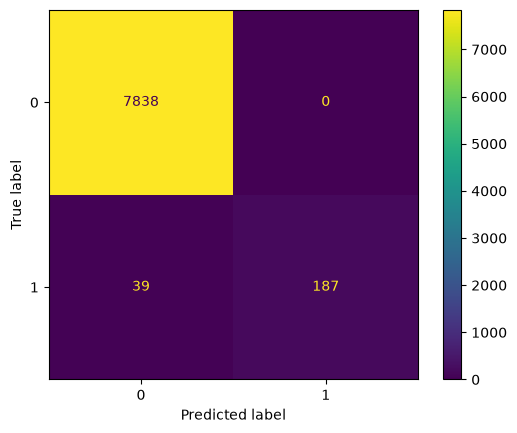

In [13]:
print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

## Which sensor matters most 

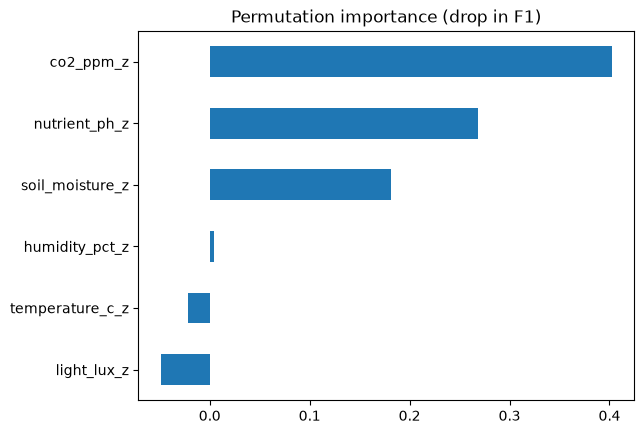

In [15]:
from sklearn.inspection import permutation_importance

result = permutation_importance(rf, X_test, y_test, scoring='f1', n_repeats=10, random_state=42, n_jobs=-1 )

importance = pd.Series(result.importances_mean, index=z_cols).sort_values()
importance.plot(kind='barh')

plt.title('Permutation importance (drop in F1)')
plt.show()


## Kmeans

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_km = df[z_cols]
inertias, silhouettes = [], []

for k in range(2,11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_km)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_km,labels, sample_size=5000,
                                        random_state=42))

best_k = np.argmax(silhouettes) + 2


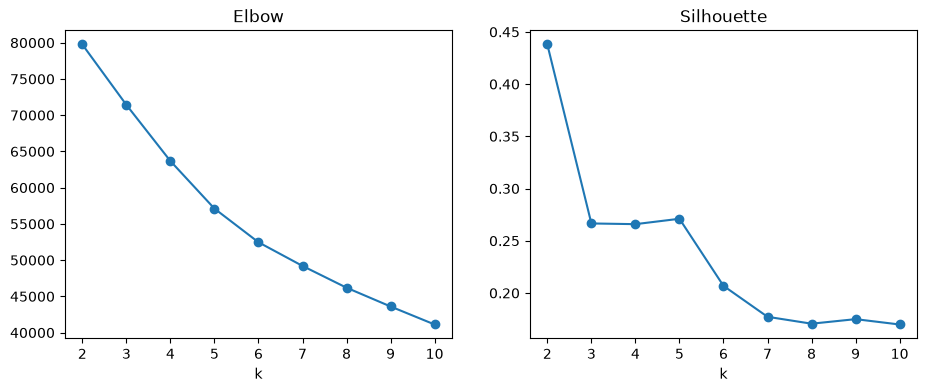

Best k by silhouette: 2


In [17]:
ks = range(2, 11)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, marker='o'); ax[0].set_title('Elbow'); ax[0].set_xlabel('k')
ax[1].plot(ks, silhouettes, marker='o'); ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
plt.show()
print('Best k by silhouette:', best_k)

## Compare cluseters to stress

In [18]:
k = 2

km = KMeans(n_clusters=k, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X_km)

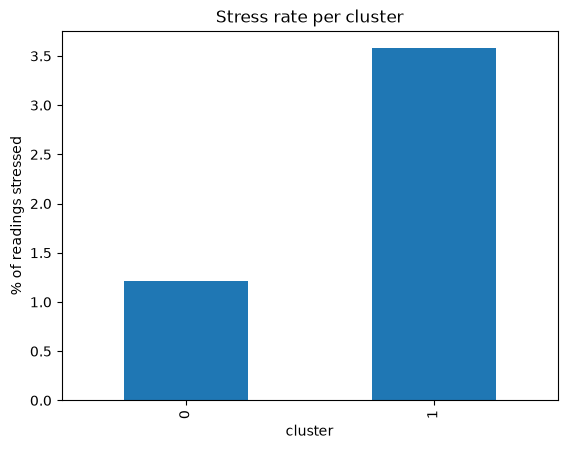

cluster
1    0.66348
0    0.33652
Name: proportion, dtype: float64


In [19]:
stress_rate = df.groupby('cluster')['plant_stress'].mean() * 100
stress_rate.plot(kind='bar')

plt.ylabel('% of readings stressed')
plt.title('Stress rate per cluster')

plt.show()

share = df[df['plant_stress'] == 1]['cluster'].value_counts(normalize=True)
print(share) #<-- the fraction of all stress events fall on each cluster

In [20]:
df.groupby('cluster')[z_cols].mean().round(2) #names the clusters

,temperature_c_z,humidity_pct_z,soil_moisture_z,light_lux_z,co2_ppm_z,nutrient_ph_z
cluster,,,,,,
0,-0.67,0.62,0.01,-0.74,0.65,0.01
1,1.00,-0.93,-0.02,1.10,-0.97,-0.01


## Recomendation - finding a threshhold 

In [21]:
top = importance.index[-1]

df.groupby('plant_stress')[top].describe()

,count,mean,std,min,25%,50%,75%,max
plant_stress,,,,,,,,
0,23669.0,0.033802,0.911050,-2.741584,-0.713432,0.309765,0.740272,2.122208
1,523.0,-1.529761,2.508339,-7.424441,-3.612641,-0.763130,0.447273,1.570685


In [22]:
for t in [-1.0, -1.5, -2.0, -2.5]:
    alert = df[top] < t
    caught = (alert & (df['plant_stress'] == 1)).sum() / (df['plant_stress']== 1).sum()
    false_alarms = (alert & (df['plant_stress'] == 0)).sum()
    print(f'{t}: catches {caught:.0%} of stress, {false_alarms} false alarms')

-1.0: catches 44% of stress, 4320 false alarms
-1.5: catches 33% of stress, 1674 false alarms
-2.0: catches 28% of stress, 315 false alarms
-2.5: catches 26% of stress, 19 false alarms


In [ ]:
co2_stats = df.groupby('zone')['co2_ppm'].agg(['mean', 'std'])
co2_stats['alert_below_ppm'] = co2_stats['mean'] - 2.5 * co2_stats['std']
co2_stats.round(0)

## Bonus 

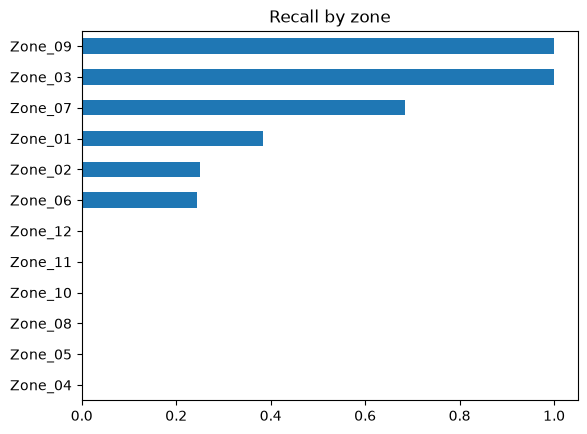

In [23]:
from sklearn.metrics import recall_score

zone_recall = {}

for z in df['zone'].unique():
    zmask = df['zone'] == z
    m = RandomForestClassifier(n_estimators=200,
                               class_weight='balanced',
                               random_state=42)
    m.fit(X[zmask & train_mask], y[zmask & train_mask])
    pred = m.predict(X[zmask & ~train_mask])
    zone_recall[z] = recall_score(y[zmask & ~ train_mask], pred, zero_division=0)

pd.Series(zone_recall).sort_values().plot(kind='barh', title='Recall by zone')
plt.show()


In [25]:
test = df[~train_mask]
test.groupby('zone')['plant_stress'].sum()

zone
Zone_01    26
Zone_02    12
Zone_03     5
Zone_04    19
Zone_05     7
Zone_06    49
Zone_07    19
Zone_08    18
Zone_09    14
Zone_10    22
Zone_11    17
Zone_12    18
Name: plant_stress, dtype: int64